In [47]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import precision_score, recall_score
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

In [48]:
#data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

#!wget $data -O data-week-3.csv

In [49]:
df = pd.read_csv('data-week-3.csv')
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [50]:
categorical = ['lead_source','industry','employment_status','location']
numericals = ['lead_score', 'number_of_courses_viewed','interaction_count','annual_income']

In [51]:
for c in df.columns:
    if c in categorical:
        df[c] = df[c].fillna('NA')
    else:
        df[c] = df[c].fillna(0)

In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [ ]:
Question 1

In [25]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']

df_train.drop(columns=['converted'], inplace=True)
df_val.drop(columns=['converted'], inplace=True)
df_test.drop(columns=['converted'], inplace=True)

In [26]:
result = {}

for var in numericals:
    score = df_train[var]
    auc = roc_auc_score(y_train, score)
    if auc < 0.5:
        auc = roc_auc_score(y_train, -score)   # invert
    result[var] = auc

print(result)

{'lead_score': 0.7882254810906102, 'number_of_courses_viewed': 0.7229894623989618, 'interaction_count': 0.7649203047563227, 'annual_income': 0.6081977776250831}


Question 2

In [27]:
dv = DictVectorizer(sparse=False)
train_dicts = df_train[categorical + numericals].to_dict(orient='records')
val_dicts = df_val[categorical + numericals].to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.fit_transform(val_dicts)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=1)
model.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1

In [28]:
print(round(roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),3))

0.732


QUestion 3

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


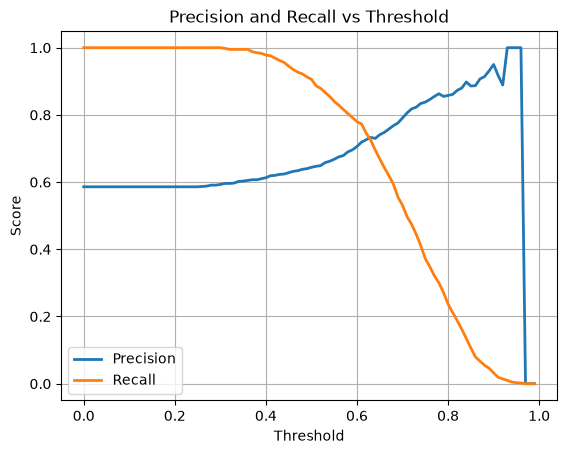

In [29]:
c = np.arange(0.0, 1.0, 0.01)
y_pred_proba = model.predict_proba(X_val)[:, 1]

precisions = []
recalls = []

for threshold in c:
    y_pred = (y_pred_proba >= threshold).astype(int)
    precision = round(precision_score(y_val, y_pred),3)
    recall = round(recall_score(y_val, y_pred),3)
    precisions.append(precision)
    recalls.append(recall)
    #print(f"Threshold: {threshold:.2f}, Precision: {precision:.3f}, Recall: {recall:.3f}")

plt.plot(c, precisions, label='Precision', linewidth=2)
plt.plot(c, recalls, label='Recall', linewidth=2)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)

Question 4

In [30]:
df_thresh = pd.DataFrame(zip(c, precisions, recalls), columns=['threshold','precision','recall'])

df_thresh['F1'] = 2 * (df_thresh['precision'] * df_thresh['recall'])/(df_thresh['precision'] + df_thresh['recall'])

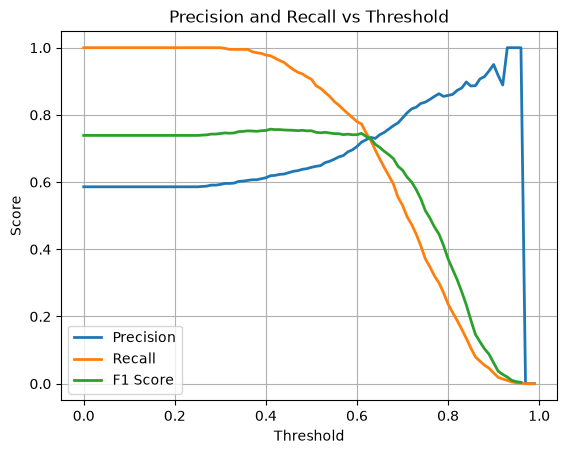

In [31]:
plt.plot(c, df_thresh['precision'], label='Precision', linewidth=2)
plt.plot(c, df_thresh['recall'], label='Recall', linewidth=2)
plt.plot(c, df_thresh['F1'], label='F1 Score', linewidth=2)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)

In [32]:
best = df_thresh.loc[df_thresh['F1'].idxmax()]
print(best)

threshold    0.410000
precision    0.619000
recall       0.976000
F1           0.757547
Name: 41, dtype: float64


Question 5

In [33]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numericals].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [34]:
def predict(df, dv, model):
    dicts = df[categorical + numericals].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [ ]:

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
score = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted']
    y_val = df_val['converted']

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    print(f"AUC: {auc:.5f}")
    score.append(auc)

print(round(np.std(score), 3))

AUC: 0.73056
AUC: 0.72957
AUC: 0.73634
AUC: 0.74125
AUC: 0.72091
0.007


Question 6

In [39]:
C = [0.000001, 0.001, 1]

In [40]:
def train(df_train, y_train, C=C):
    dicts = df_train[categorical + numericals].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [45]:
def cross_validation(df_full_train, C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted']
        y_val = df_val['converted']

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    return np.mean(scores), np.std(scores)

In [46]:
for c in C:
    train(df_full_train, df_full_train['converted'], C=c)
    mean_auc, std_auc = cross_validation(df_full_train, C=c)
    print(f"C: {c}, Mean AUC: {mean_auc:.5f}, Std AUC: {std_auc:.5f}")

C: 1e-06, Mean AUC: 0.61673, Std AUC: 0.01867
C: 0.001, Mean AUC: 0.74917, Std AUC: 0.01000
C: 1, Mean AUC: 0.73173, Std AUC: 0.00685
